# DAML Homework 3 — Orbital Black Box
## Recover hidden spacecraft modes from unlabeled telemetry

**Mandatory core: 35–45 minutes · Optional deep dive: 45–90+ minutes · 100 required points + up to 10 bonus points**

A small research satellite lost the mode labels in its telemetry log. The sensor readings survived—but nobody marked which time windows corresponded to quiet observation, high-power communication, or attitude maneuvers.

Your job is to discover recurring structure **without using labels**, visualize it, and decide when the resulting categories deserve trust.

<div style="border-left: 5px solid #2f855a; padding: 0.8em 1em; background: #f0fff4;">
<b>Learning objectives</b><br>
By the end, you should be able to:
<ol>
  <li>implement the assignment and centroid-update steps of K-means;</li>
  <li>measure K-means fit with inertia and compare random restarts;</li>
  <li>replace hard assignments with soft memberships and weighted updates;</li>
  <li>compute a PCA projection by centering data and using SVD;</li>
  <li>explain why an unsupervised cluster is a model-dependent pattern—not automatically a real-world category.</li>
</ol>
</div>

<div style="border-left: 5px solid #3182ce; padding: 0.8em 1em; background: #ebf8ff;">
<b>How this homework is scaffolded</b><br><br>
Every required algorithm begins with a worked miniature example, a shape diagram or recipe, and an immediate public check. Most required TODOs are one to four lines. The data generator, feature scaling, K-means loop, restart comparison, plots, and diagnostic dashboard are supplied.<br><br>
You are implementing the <i>ideas</i>, not wrestling the notebook infrastructure. Tiny mercy. Huge win.
</div>

## Working policy: make a real attempt first

AI tools may be used **as a tutor when you are stuck**, after you have made a fair initial attempt. Good uses include requesting a hint, asking what an array shape means, or debugging an error message.

You must understand every submitted line. This course is cumulative, and later individual assessment will test the same ideas without an assistant beside you.

Complete the short assistance disclosure near the end. The disclosure itself is ungraded.

## Submission contract

- Complete only cells marked **YOUR CODE** or **YOUR RESPONSE**.
- Keep every required function name and signature unchanged.
- Use NumPy and Matplotlib only in the mandatory section; do not call scikit-learn clustering, mixture, or PCA implementations.
- Do not use or invent ground-truth mode labels. The point is to reason from unlabeled structure.
- Before submitting, restart the runtime/kernel and run all required cells.
- Submit exactly one `.ipynb` file: `DAML_HW03_Orbital_Black_Box.ipynb`.

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import permutations

np.set_printoptions(precision=4, suppress=True)

## Mission setup

Each row is one short telemetry window. The six columns have different units and scales:

1. bus power draw;
2. reaction-wheel vibration;
3. thermal gradient;
4. radio activity;
5. attitude error;
6. magnetic noise.

The generator below creates a reproducible sequence with three recurring—but deliberately unnamed—operating patterns. The hidden mode sequence is discarded before you receive the matrix.

In [36]:
FEATURE_NAMES = np.array([
    "bus_power_w",
    "wheel_vibration_g",
    "thermal_gradient_c",
    "radio_activity",
    "attitude_error_deg",
    "magnetic_noise",
])

def make_orbital_telemetry(n_steps=240, seed=17):
    """Return an unlabeled telemetry matrix with three recurring hidden modes."""
    rng = np.random.default_rng(seed)

    transition = np.array([
        [0.93, 0.05, 0.02],
        [0.06, 0.90, 0.04],
        [0.04, 0.08, 0.88],
    ])
    hidden_state = np.zeros(n_steps, dtype=int)
    for t in range(1, n_steps):
        hidden_state[t] = rng.choice(3, p=transition[hidden_state[t - 1]])

    latent_means = np.array([
        [-1.50, -0.60,  0.20],
        [ 1.45, -0.10, -0.45],
        [ 0.20,  1.25,  0.65],
    ])
    latent_covariances = np.array([
        [[0.32,  0.08,  0.00], [ 0.08, 0.22, 0.03], [ 0.00, 0.03, 0.16]],
        [[0.30, -0.06,  0.03], [-0.06, 0.25, 0.00], [ 0.03, 0.00, 0.22]],
        [[0.38,  0.04, -0.03], [ 0.04, 0.30, 0.05], [-0.03, 0.05, 0.24]],
    ])

    latent = np.empty((n_steps, 3))
    for t in range(n_steps):
        mean = latent_means[hidden_state[t]].copy()
        if t > 0 and hidden_state[t] != hidden_state[t - 1]:
            # Transitions look ambiguous because the spacecraft does not switch instantly.
            mean = 0.50 * latent_means[hidden_state[t - 1]] + 0.50 * latent_means[hidden_state[t]]
        latent[t] = rng.multivariate_normal(mean, latent_covariances[hidden_state[t]])

    mixing = np.array([
        [ 1.2,  0.2, -0.1],
        [ 0.1,  1.0,  0.3],
        [-0.5,  0.2,  0.8],
        [ 0.7, -0.6,  0.1],
        [ 0.2,  0.4,  1.1],
        [-0.8,  0.1,  0.4],
    ])
    observed = latent @ mixing.T + rng.normal(scale=0.16, size=(n_steps, 6))

    scales = np.array([35.0, 0.8, 18.0, 120.0, 2.5, 0.04])
    offsets = np.array([120.0, 2.0, 60.0, 400.0, 8.0, 0.2])
    return observed * scales + offsets

X_raw = make_orbital_telemetry()
print("Telemetry shape:", X_raw.shape)

Telemetry shape: (240, 6)


### Scale checkpoint — provided

K-means uses Euclidean distance. If one feature varies by hundreds of units while another varies by hundredths, the large-unit feature can dominate the geometry even when it is not more informative.

We therefore standardize each feature using statistics computed from this unlabeled dataset:

$$
x_{ij}^{\text{standardized}}=\frac{x_{ij}-\mu_j}{\sigma_j}.
$$

In [37]:
def standardize_features(X):
    """Provided helper: standardize columns and return data, means, and stds."""
    X = np.asarray(X, dtype=float)
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    if np.any(std == 0):
        raise ValueError("every feature must vary")
    return (X - mean) / std, mean, std

X, feature_mean, feature_std = standardize_features(X_raw)

print("Raw feature standard deviations:")
for name, value in zip(FEATURE_NAMES, feature_std):
    print(f"  {name:24s} {value:10.4f}")
print("\nStandardized column means:", X.mean(axis=0))
print("Standardized column stds: ", X.std(axis=0))

Raw feature standard deviations:
  bus_power_w                 59.6198
  wheel_vibration_g            0.6078
  thermal_gradient_c          16.6975
  radio_activity             103.4077
  attitude_error_deg           1.7343
  magnetic_noise               0.0468

Standardized column means: [-0.  0. -0.  0.  0.  0.]
Standardized column stds:  [1. 1. 1. 1. 1. 1.]


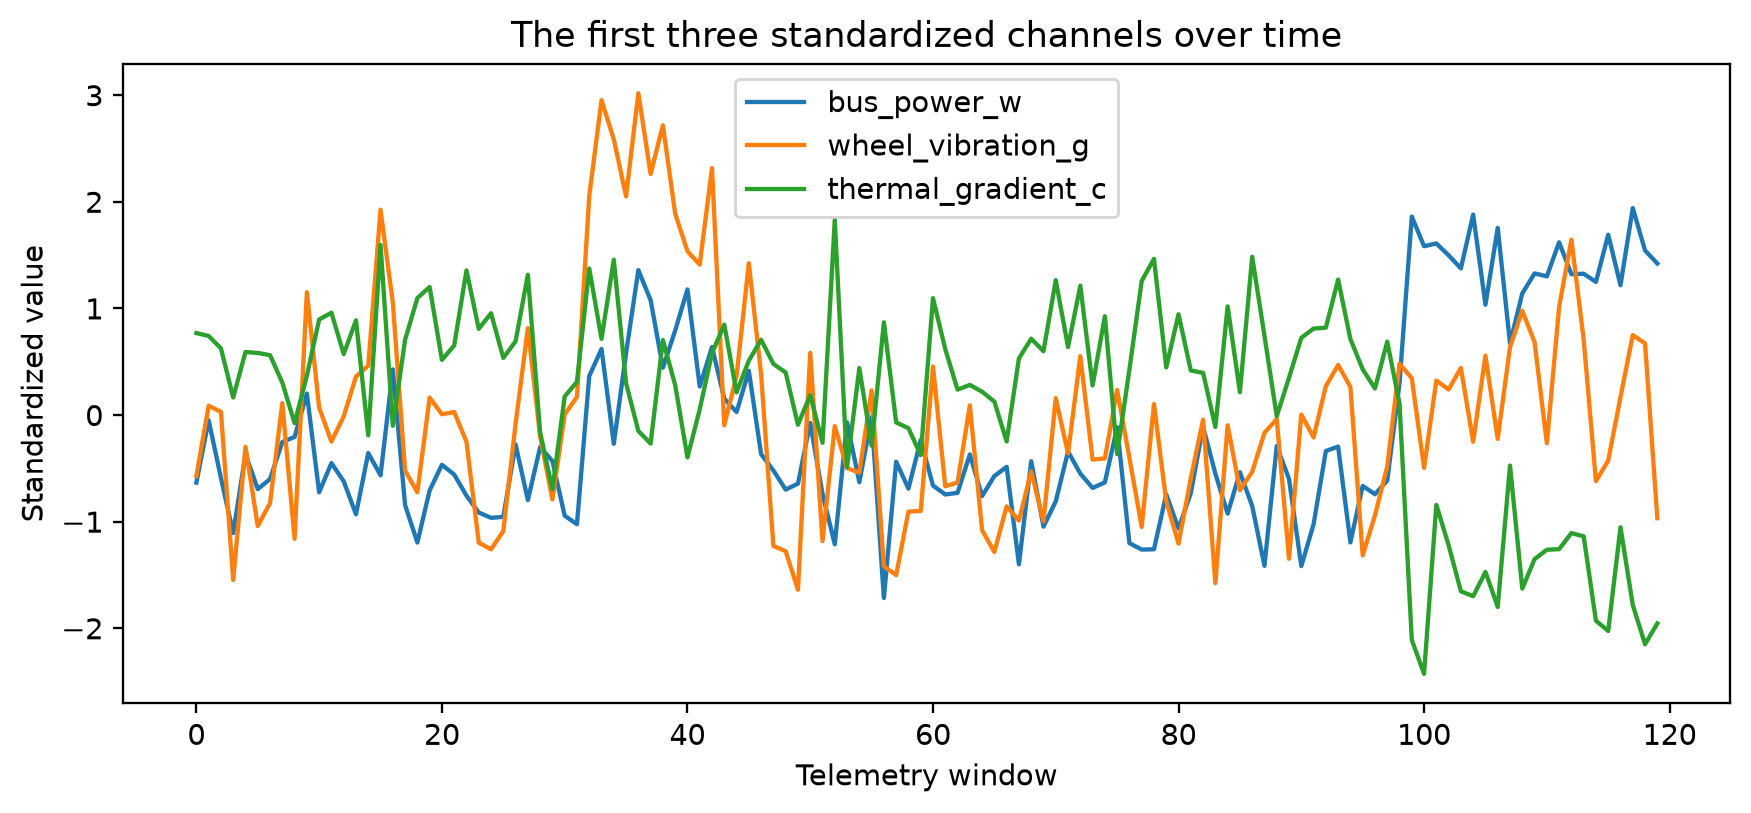

In [38]:
plt.figure(figsize=(10, 4))
for column in range(3):
    plt.plot(X[:120, column], label=FEATURE_NAMES[column])
plt.xlabel("Telemetry window")
plt.ylabel("Standardized value")
plt.title("The first three standardized channels over time")
plt.legend()
plt.show()

# Part 1 — K-means: assign, update, repeat (55 points, ~19 minutes)

K-means alternates between two ideas from lecture:

1. **Estimate:** assign each point to the closest centroid.
2. **Optimize:** move each centroid to the mean of its assigned points.

The loop is supplied. You will build the four mathematical pieces it calls.

## 1A. Squared distances (15 points)

For `n` points, `k` centers, and `d` features:

- `X[:, None, :]` has shape `(n, 1, d)`;
- `centers[None, :, :]` has shape `(1, k, d)`;
- their difference has shape `(n, k, d)`.

Sum the squared differences over the **feature axis** to obtain `(n, k)`.

We use squared distance because square root is monotonic: it would not change the nearest center.

In [39]:
X_demo = np.array([
    [0.0, 0.0],
    [1.0, 0.0],
    [0.0, 2.0],
])
centers_demo = np.array([
    [0.0, 0.0],
    [2.0, 0.0],
])

demo_differences = X_demo[:, None, :] - centers_demo[None, :, :]
print("Difference tensor shape:", demo_differences.shape)
print("Expected squared-distance matrix:\n", np.array([[0.0, 4.0], [1.0, 1.0], [4.0, 8.0]]))

Difference tensor shape: (3, 2, 2)
Expected squared-distance matrix:
 [[0. 4.]
 [1. 1.]
 [4. 8.]]


In [40]:
def squared_distances(X, centers):
    """Return all point-to-center squared distances with shape (n, k)."""
    X = np.asarray(X, dtype=float)
    centers = np.asarray(centers, dtype=float)
    if X.ndim != 2 or centers.ndim != 2:
        raise ValueError("X and centers must both be 2D")
    if X.shape[1] != centers.shape[1]:
        raise ValueError("X and centers must have the same number of features")
    if len(centers) == 0:
        raise ValueError("at least one center is required")

    differences = X[:, None, :] - centers[None, :, :]

    # TODO: square the differences and sum over the feature axis.
    sum_squared_differences = np.sum(differences ** 2, axis = 2)

    return sum_squared_differences
    raise NotImplementedError("Complete squared_distances")

In [41]:
expected = np.array([[0.0, 4.0], [1.0, 1.0], [4.0, 8.0]])
actual = squared_distances(X_demo, centers_demo)
assert actual.shape == (3, 2)
assert np.allclose(actual, expected)
print("✓ Public check passed")

✓ Public check passed


## 1B. Hard cluster assignment (10 points)

Each row of the distance matrix belongs to one observation. Choose the smallest entry in each row.

**Tie rule:** `np.argmin` returns the first minimum, so an exact tie goes to the smaller cluster index.

In [42]:
def assign_clusters(X, centers):
    """Return the index of the closest center for each row of X."""
    distances = squared_distances(X, centers)

    return np.argmin(distances, axis = 1)

    # TODO: take argmin across the center columns.
    raise NotImplementedError("Complete assign_clusters")

In [43]:
labels_demo = assign_clusters(X_demo, centers_demo)
assert np.array_equal(labels_demo, np.array([0, 0, 0]))
tie_label = assign_clusters(np.array([[1.0, 0.0]]), centers_demo)
assert np.array_equal(tie_label, np.array([0]))
print("✓ Public check passed")

✓ Public check passed


## 1C. Recenter each cluster (20 points)

**Recipe**

1. Copy the old centers so the input is not modified.
2. For each cluster index, select rows whose label equals that index.
3. If the cluster has members, replace its center with their feature-wise mean.
4. If a cluster is empty, keep its previous center. This avoids producing `NaN` values.

In [44]:
def update_centers(X, labels, old_centers):
    """Return K-means centroids, keeping an old center for an empty cluster."""
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels, dtype=int)
    old_centers = np.asarray(old_centers, dtype=float)
    if X.ndim != 2 or old_centers.ndim != 2:
        raise ValueError("X and old_centers must both be 2D")
    if X.shape[1] != old_centers.shape[1]:
        raise ValueError("X and old_centers must have the same number of features")
    if labels.shape != (len(X),):
        raise ValueError("labels must contain one cluster index per row")
    if np.any((labels < 0) | (labels >= len(old_centers))):
        raise ValueError("labels contain an invalid cluster index")

    new_centers = old_centers.copy()
    for cluster_id in range(len(old_centers)):
        members = X[labels == cluster_id]
        if len(members) > 0:
            new_centers[cluster_id] = np.mean(members, axis = 0)
        # TODO: when members is nonempty, replace this center with their mean.

    return new_centers

In [45]:
X_small = np.array([[0.0, 0.0], [2.0, 0.0], [8.0, 2.0]])
old_small = np.array([[0.0, 0.0], [9.0, 3.0], [50.0, 50.0]])
labels_small = np.array([0, 0, 1])
expected_small = np.array([[1.0, 0.0], [8.0, 2.0], [50.0, 50.0]])
assert np.allclose(update_centers(X_small, labels_small, old_small), expected_small)
assert np.allclose(old_small, np.array([[0.0, 0.0], [9.0, 3.0], [50.0, 50.0]]))
print("✓ Public check passed")

✓ Public check passed


## 1D. Inertia: how tightly do points fit their assigned centers? (10 points)

K-means minimizes the sum of squared distances to assigned centers:

$$
J=\sum_{i=1}^{n}\lVert x_i-\mu_{z_i}\rVert_2^2.
$$

Use advanced indexing to select one distance from each row of the `(n, k)` matrix.

In [46]:
def kmeans_inertia(X, labels, centers):
    """Return the sum of squared distances to assigned centers."""
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels, dtype=int)
    centers = np.asarray(centers, dtype=float)
    if labels.shape != (len(X),):
        raise ValueError("labels must contain one cluster index per row")
    if np.any((labels < 0) | (labels >= len(centers))):
        raise ValueError("labels contain an invalid cluster index")

    distances = squared_distances(X, centers)

    min_distance = distances[np.arange(len(X)), labels]
    return np.sum(min_distance)
    # TODO 1: select each row's distance to its assigned center.
    # TODO 2: sum those distances and return a Python float.
    raise NotImplementedError("Complete kmeans_inertia")

In [47]:
labels_tiny = np.array([0, 0, 1])
centers_tiny = np.array([[1.0, 0.0], [8.0, 2.0]])
assert np.isclose(kmeans_inertia(X_small, labels_tiny, centers_tiny), 2.0)
print("✓ Public check passed")

✓ Public check passed


## Run K-means from several initializations — provided

K-means can converge to different local solutions because the starting centers change its path. We therefore run the algorithm from several seeds and keep the run with the lowest final inertia.

**Important:** inertia is useful for comparing runs on the same scaled data with the same `k`. It does not prove that the clusters correspond to real spacecraft modes.

In [48]:
def fit_kmeans_guided(X, k=3, seed=0, max_iter=100, tolerance=1e-8):
    """Provided K-means loop built from the four functions above."""
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(seed)
    initial_indices = rng.choice(len(X), size=k, replace=False)
    centers = X[initial_indices].copy()
    history = []

    for _ in range(max_iter):
        labels = assign_clusters(X, centers)
        new_centers = update_centers(X, labels, centers)
        new_labels = assign_clusters(X, new_centers)
        history.append(kmeans_inertia(X, new_labels, new_centers))

        if np.allclose(new_centers, centers, atol=tolerance, rtol=0.0):
            centers = new_centers
            labels = new_labels
            break

        centers = new_centers
        labels = new_labels

    return labels, centers, np.asarray(history, dtype=float)

def best_label_agreement(labels_a, labels_b, k=3):
    """Compare clusterings after accounting for arbitrary label names."""
    labels_a = np.asarray(labels_a, dtype=int)
    labels_b = np.asarray(labels_b, dtype=int)
    best = 0.0
    for permutation in permutations(range(k)):
        mapped = np.array([permutation[label] for label in labels_a])
        best = max(best, float(np.mean(mapped == labels_b)))
    return best

In [49]:
restart_seeds = [2, 7, 14, 21, 44]
runs = []

for seed in restart_seeds:
    labels, centers, history = fit_kmeans_guided(X, k=3, seed=seed)
    runs.append({
        "seed": seed,
        "labels": labels,
        "centers": centers,
        "history": history,
        "inertia": float(history[-1]),
    })

best_run = min(runs, key=lambda run: run["inertia"])
best_labels = best_run["labels"]
best_centers = best_run["centers"]

print("seed | final inertia | cluster sizes | agreement with selected run")
print("-----|---------------|---------------|----------------------------")
for run in runs:
    sizes = np.bincount(run["labels"], minlength=3)
    agreement = best_label_agreement(run["labels"], best_labels, k=3)
    print(f"{run['seed']:4d} | {run['inertia']:13.3f} | {str(sizes):13s} | {agreement:8.1%}")

print("\nSelected seed:", best_run["seed"])

seed | final inertia | cluster sizes | agreement with selected run
-----|---------------|---------------|----------------------------
   2 |       461.837 | [144  35  61] |   100.0%
   7 |       461.837 | [144  35  61] |   100.0%
  14 |       462.622 | [149  30  61] |    97.9%
  21 |       462.622 | [149  61  30] |    97.9%
  44 |       461.837 | [ 35  61 144] |   100.0%

Selected seed: 2


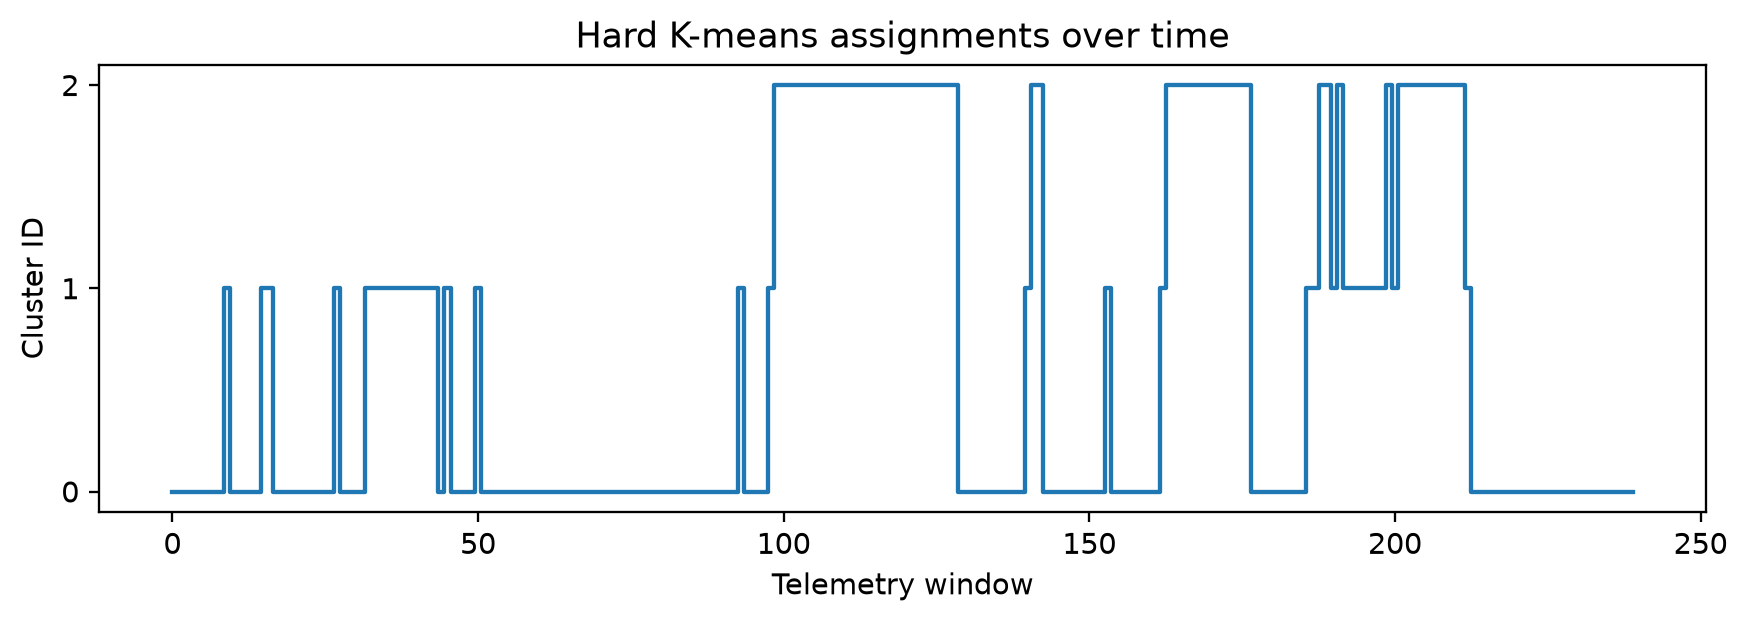

In [50]:
plt.figure(figsize=(10, 2.8))
plt.step(np.arange(len(best_labels)), best_labels, where="mid")
plt.yticks([0, 1, 2])
plt.xlabel("Telemetry window")
plt.ylabel("Cluster ID")
plt.title("Hard K-means assignments over time")
plt.show()

# Part 2 — A softer view: membership instead of certainty (25 points, ~10 minutes)

Hard K-means makes an all-or-nothing choice. The lecture's EM discussion asks a more nuanced question: **what if a point fits more than one cluster?**

We will build a distance-based bridge to EM:

$$
r_{ik}=\frac{\exp(-d_{ik}^2/\tau)}{\sum_j\exp(-d_{ij}^2/\tau)}.
$$

Here `temperature` $\tau$ controls softness. These values are useful model-based memberships, but they are **not calibrated real-world probabilities** unless stronger probabilistic assumptions are justified.

## 2A. Soft memberships (15 points)

**Numerically stable recipe**

1. Convert squared distances into negative logits.
2. Subtract each row's maximum logit before exponentiating.
3. Normalize each row to sum to one.

In [51]:
def soft_memberships(X, centers, temperature=1.0):
    """Return distance-based soft memberships with shape (n, k)."""
    if not np.isscalar(temperature) or temperature <= 0:
        raise ValueError("temperature must be a positive scalar")

    distances = squared_distances(X, centers)
    logits = -distances / float(temperature)

    # Stability step: make the largest logit in every row equal zero.
    logits = logits - logits.max(axis=1, keepdims=True)

    # TODO 1: exponentiate the stabilized logits.
    exp_logits = np.exp(logits)
    # TODO 2: divide each row by its row sum.
    # print(exp_logits)
    # print(np.sum(exp_logits, axis = 1, keepdims = True))
    exp_logits = exp_logits / (np.sum(exp_logits, axis = 1, keepdims= True))

    return exp_logits
    raise NotImplementedError("Complete soft_memberships")

In [52]:
X_soft_demo = np.array([[0.0], [1.0], [2.0]])
centers_soft_demo = np.array([[0.0], [2.0]])
memberships_demo = soft_memberships(X_soft_demo, centers_soft_demo, temperature=1.0)

assert memberships_demo.shape == (3, 2)
assert np.allclose(memberships_demo.sum(axis=1), 1.0)
assert memberships_demo[0, 0] > memberships_demo[0, 1]
assert np.allclose(memberships_demo[1], np.array([0.5, 0.5]))
print("✓ Public check passed")

✓ Public check passed


## 2B. Weighted center update (10 points)

The lecture's weighted-center example used a point at `2` with weight `0.9` and a point at `8` with weight `0.1`:

$$
\frac{0.9(2)+0.1(8)}{0.9+0.1}=2.6.
$$

For every cluster at once:

- cluster mass: `responsibilities.sum(axis=0)`;
- weighted sum: `responsibilities.T @ X`;
- weighted center: weighted sum divided by cluster mass.

In [53]:
def weighted_centers(X, responsibilities):
    """Return one responsibility-weighted center per cluster."""
    X = np.asarray(X, dtype=float)
    responsibilities = np.asarray(responsibilities, dtype=float)
    if X.ndim != 2 or responsibilities.ndim != 2:
        raise ValueError("X and responsibilities must both be 2D")
    if len(X) != len(responsibilities):
        raise ValueError("responsibilities must have one row per observation")
    if np.any(responsibilities < 0):
        raise ValueError("responsibilities must be nonnegative")

    cluster_mass = responsibilities.sum(axis=0)
    if np.any(cluster_mass <= 0):
        raise ValueError("every cluster must receive positive total responsibility")

    # TODO 1: compute weighted sums with responsibilities.T @ X.
    weighted_sum = responsibilities.T @ X
    # TODO 2: divide each cluster row by its mass.
    weighted_center = weighted_sum / cluster_mass[:, None]

    return weighted_center
    raise NotImplementedError("Complete weighted_centers")

In [54]:
X_weight_demo = np.array([[2.0], [8.0]])
R_weight_demo = np.array([[0.9, 0.1], [0.1, 0.9]])
expected_weighted = np.array([[2.6], [7.4]])
assert np.allclose(weighted_centers(X_weight_demo, R_weight_demo), expected_weighted)
print("✓ Public check passed")

✓ Public check passed


In [55]:
temperature = 3.0
responsibilities = soft_memberships(X, best_centers, temperature=temperature)
soft_updated_centers = weighted_centers(X, responsibilities)
membership_confidence = responsibilities.max(axis=1)

print("Soft-center movement from the hard K-means centers:")
print(np.linalg.norm(soft_updated_centers - best_centers, axis=1))

print("\nMembership confidence quantiles:")
for q in [0.00, 0.10, 0.25, 0.50, 0.75, 0.90, 1.00]:
    print(f"  q={q:4.2f}: {np.quantile(membership_confidence, q):.3f}")

ambiguous = np.argsort(membership_confidence)[:8]
print("\nEight most ambiguous windows:")
for index in ambiguous:
    print(
        f"  t={index:3d}  hard={best_labels[index]}  "
        f"confidence={membership_confidence[index]:.3f}  "
        f"memberships={responsibilities[index]}"
    )

Soft-center movement from the hard K-means centers:
[0.0263 0.5529 0.0941]

Membership confidence quantiles:
  q=0.00: 0.504
  q=0.10: 0.696
  q=0.25: 0.869
  q=0.50: 0.957
  q=0.75: 0.988
  q=0.90: 0.997
  q=1.00: 0.999

Eight most ambiguous windows:
  t= 98  hard=1  confidence=0.504  memberships=[0.3786 0.5045 0.1169]
  t=212  hard=1  confidence=0.512  memberships=[0.4011 0.5117 0.0872]
  t= 46  hard=0  confidence=0.513  memberships=[0.5129 0.4729 0.0142]
  t=140  hard=1  confidence=0.514  memberships=[0.4516 0.5145 0.034 ]
  t=153  hard=1  confidence=0.519  memberships=[0.4544 0.5188 0.0268]
  t=191  hard=2  confidence=0.520  memberships=[0.09   0.3903 0.5196]
  t=239  hard=0  confidence=0.536  memberships=[0.5361 0.2749 0.189 ]
  t=146  hard=0  confidence=0.540  memberships=[0.54   0.4164 0.0436]


# Part 3 — Compress the telemetry with PCA (15 points, ~7 minutes)

Six features are difficult to visualize directly. PCA finds orthogonal directions of greatest variation.

**Recipe**

1. Compute the feature mean and center `X`.
2. Run `np.linalg.svd(centered, full_matrices=False)`.
3. Keep the first `n_components` rows of `Vt`.
4. Project with `centered @ components.T`.
5. Compute explained-variance ratios from squared singular values.

PCA centers but does not automatically standardize, which is why we already scaled the telemetry before this section.

In [56]:
def pca_project(X, n_components=2):
    """Return projected data, components, mean, and explained-variance ratios."""
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) < 2:
        raise ValueError("X must be a 2D array with at least two rows")
    max_components = min(X.shape)
    if not isinstance(n_components, (int, np.integer)) or not 1 <= n_components <= max_components:
        raise ValueError("n_components must be an integer from 1 through min(X.shape)")

    mean = X.mean(axis=0)
    centered = X - mean
    _, singular_values, Vt = np.linalg.svd(centered, full_matrices=False)

    # TODO 1: keep the first n_components rows of Vt.
    Vt = Vt[:n_components, :]
    # TODO 2: project centered data onto those component rows.
    projected_centered = centered @ Vt.T
    # TODO 3: divide the retained squared singular values by the total.
    return projected_centered, Vt, mean, singular_values[:n_components] ** 2 / np.sum(singular_values ** 2)
    raise NotImplementedError("Complete pca_project")

In [57]:
X_line = np.array([[-2.0, 0.0], [-1.0, 0.0], [1.0, 0.0], [2.0, 0.0]])
Z_line, components_line, mean_line, ratio_line = pca_project(X_line, n_components=2)

assert Z_line.shape == (4, 2)
assert components_line.shape == (2, 2)
assert np.allclose(mean_line, np.array([0.0, 0.0]))
assert np.allclose(ratio_line, np.array([1.0, 0.0]))
assert np.allclose(Z_line @ components_line + mean_line, X_line)
print("✓ Public check passed")

✓ Public check passed


Explained variance ratio: [0.6301 0.2902]
Variance captured by two components: 0.92033904164019


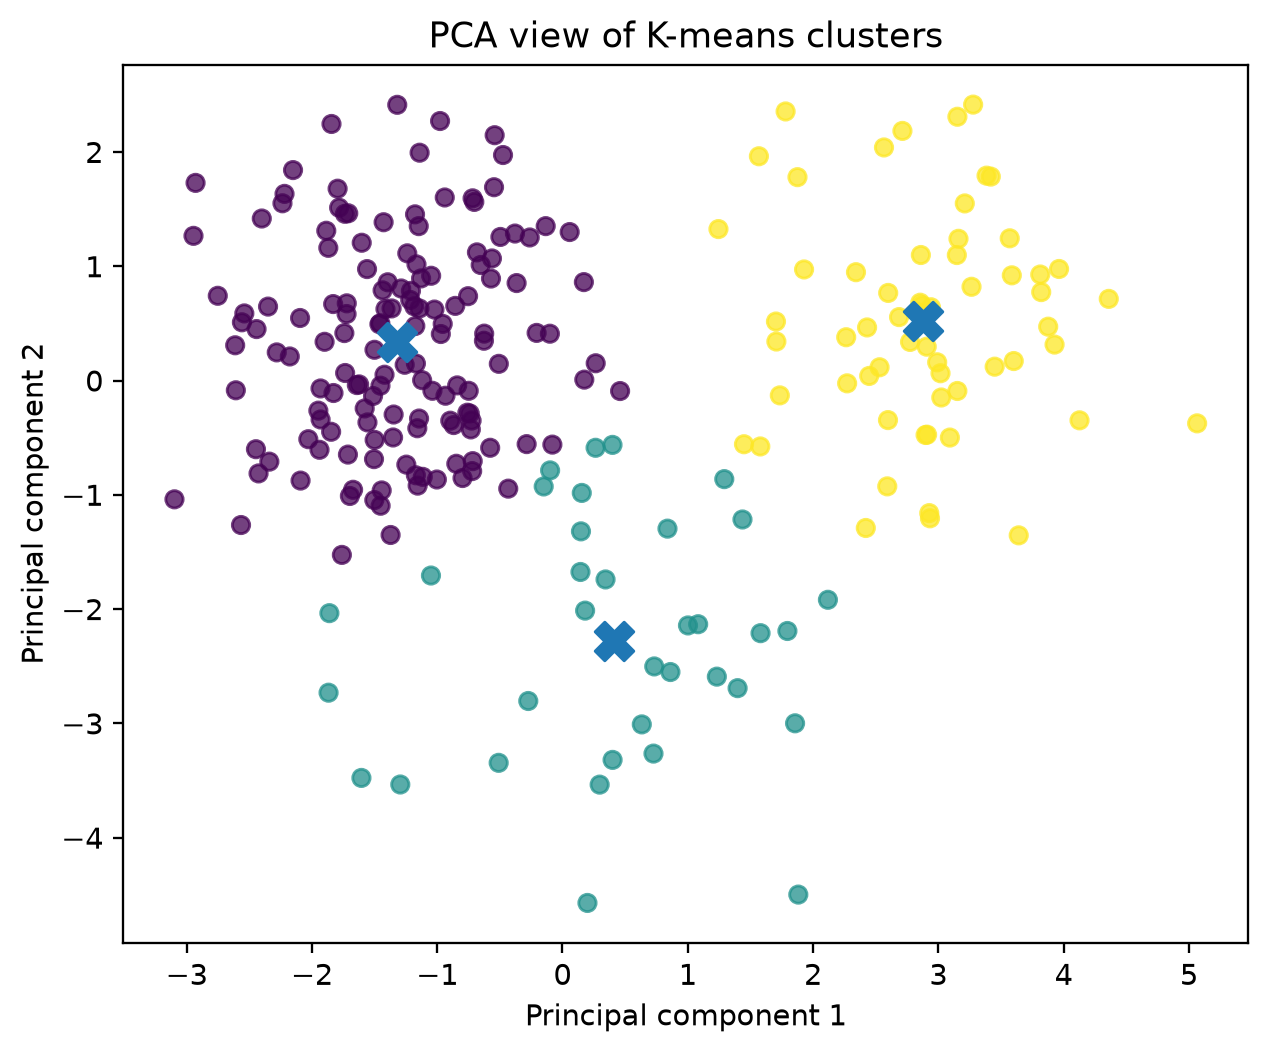

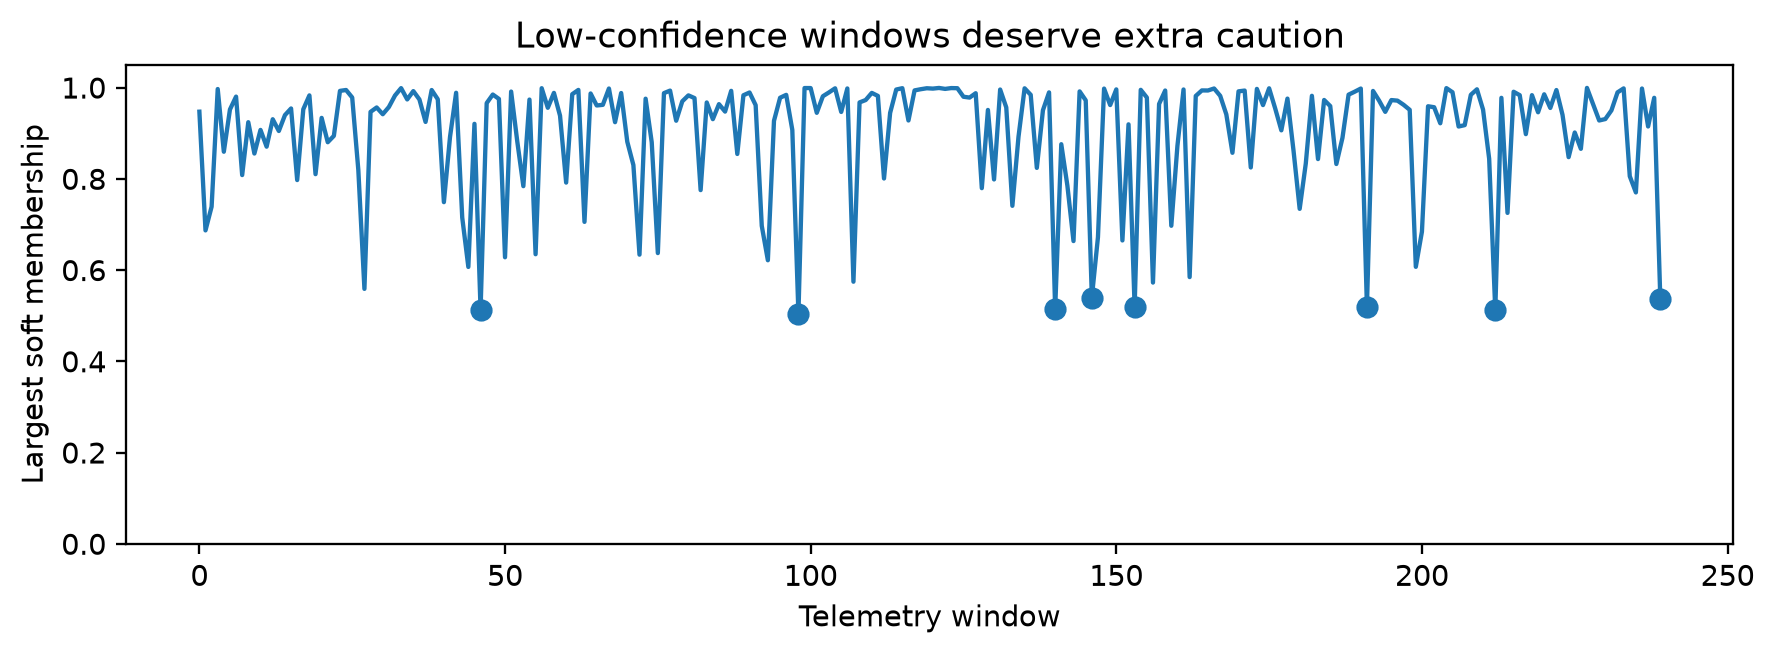

In [58]:
X_pca, pca_components, pca_mean, explained_ratio = pca_project(X, n_components=2)
projected_centers = (best_centers - pca_mean) @ pca_components.T

print("Explained variance ratio:", explained_ratio)
print("Variance captured by two components:", explained_ratio.sum())

plt.figure(figsize=(7, 5.5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=best_labels, alpha=0.75)
plt.scatter(projected_centers[:, 0], projected_centers[:, 1], marker="X", s=180)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("PCA view of K-means clusters")
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(membership_confidence)
plt.scatter(ambiguous, membership_confidence[ambiguous], s=45)
plt.ylim(0.0, 1.05)
plt.xlabel("Telemetry window")
plt.ylabel("Largest soft membership")
plt.title("Low-confidence windows deserve extra caution")
plt.show()

## Diagnostic dashboard — ungraded synthesis

Before assigning meaning to a cluster, ask:

- **Initialization stability:** do different restarts agree after relabeling?
- **Membership confidence:** are many points split between clusters?
- **Visual separation:** do clusters separate in a lower-dimensional view?
- **Model assumptions:** is Euclidean distance on standardized features a sensible notion of similarity?
- **External validity:** do clusters line up with independent engineering logs or expert interpretation?

No single diagnostic proves that a discovered category is “real.” Agreement among several diagnostics makes the case stronger.

In [59]:
restart_agreements = np.array([
    best_label_agreement(run["labels"], best_labels, k=3)
    for run in runs
])

print("Selected-run inertia:", best_run["inertia"])
print("Mean restart agreement:", restart_agreements.mean())
print("Minimum restart agreement:", restart_agreements.min())
print("Median membership confidence:", np.median(membership_confidence))
print("Fraction with confidence below 0.70:", np.mean(membership_confidence < 0.70))
print("PCA variance captured by two components:", explained_ratio.sum())

Selected-run inertia: 461.8366620601619
Mean restart agreement: 0.9916666666666666
Minimum restart agreement: 0.9791666666666666
Median membership confidence: 0.9569381820421525
Fraction with confidence below 0.70: 0.10833333333333334
PCA variance captured by two components: 0.92033904164019


# Part 4 — Decide what deserves trust (5 points, ~4 minutes)

### YOUR RESPONSE

In **4–6 sentences**, answer both prompts:

1. Use at least **two** diagnostics from the notebook—restart agreement, membership confidence, PCA separation, cluster sizes, or inertia—to explain what makes these clusters more or less trustworthy. Identify at least one reason for caution.
2. Why can you not declare that “cluster 0 is standby mode” merely because the algorithm returned ID `0`? What outside evidence would be needed to attach a real engineering meaning to a cluster?

**Response:** 

1. If PCA separation results in pretty clear, separated clusters, that is a good indication that the clusters are logically being classified. If the PCA view resulted in unclear clusters where there is not any one clear divide among categories, then that is an indication that the data is not easily split into groups, or that k-means clustering is not the best method of separation. One reason for caution would be if there is not a lot of confidence regarding membership of a certain cluster, because that would indicate that the clusters might have a lot of overlap and not many distinguishing characteristics.

2. You can't declare the cluster 0 is standby mode because ID 0 has no meaning, and could very well be ID 1 or ID 2 with a different initialization seed. We would need some real, labeled data of the categories to validate such an assessment.

## Submission checklist

- [ ] Every required public check passes.
- [ ] The notebook runs from top to bottom after a fresh restart.
- [ ] You did not call a ready-made clustering, mixture, or PCA estimator in the mandatory section.
- [ ] Your response uses at least two diagnostics and distinguishes pattern discovery from semantic truth.
- [ ] You completed the assistance disclosure below.

**Disclosure:** None / replace with a brief note about people, AI tools, or other help used.

# Optional Deep Dive — Better starts, latent programs, and temporal memory

**Estimated time: 45–90+ minutes · Up to 10 bonus points**

The mandatory section covered K-means, a soft-assignment bridge to EM, and PCA. These extensions connect the same telemetry story to three additional lecture ideas:

- smarter initialization;
- non-negative matrix factorization;
- hidden Markov models.

Leave a flag `False` to skip that section during **Restart → Run all**.

In [60]:
RUN_BONUS_A = True
RUN_BONUS_B = True
RUN_BONUS_C = True

## Bonus A — K-means++ initialization (3 points)

Random centers can begin in the same region. K-means++ spreads them out:

1. choose the first center uniformly from the rows;
2. compute each row's squared distance to its nearest chosen center;
3. sample the next center with probability proportional to that distance;
4. repeat until `k` centers have been selected.

In [61]:
def kmeans_plus_plus_init(X, k, seed=0):
    """Choose k initial centers with the K-means++ sampling rule."""
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or not isinstance(k, (int, np.integer)) or not 1 <= k <= len(X):
        raise ValueError("k must be an integer from 1 through len(X)")

    rng = np.random.default_rng(seed)
    centers = [X[rng.integers(len(X))].copy()]

    while len(centers) < k:
        current = np.asarray(centers)

        # TODO 1: find each point's squared distance to its nearest chosen center.

        distances = X[:, None, :] - current
        squared_distances = distances ** 2

        # TODO 2: normalize those distances into probabilities.

        probabilities = squared_distances / sum(squared_distances)
        probabilities = probabilities.flatten()
        # TODO 3: sample the next row with rng.choice(..., p=probabilities).

        sample = rng.choice(X, p = probabilities)
        centers.append(sample)

        # raise NotImplementedError("Complete kmeans_plus_plus_init")

    return np.asarray(centers)

In [62]:
if RUN_BONUS_A:
    init_demo = kmeans_plus_plus_init(np.array([[0.0], [1.0], [10.0], [11.0]]), 2, seed=4)
    assert init_demo.shape == (2, 1)
    assert len(np.unique(init_demo[:, 0])) == 2
    print("✓ Bonus A public check passed")

✓ Bonus A public check passed


## Bonus B — One NMF multiplicative update (4 points)

NMF represents a nonnegative matrix as

$$
X\approx WH,
$$

where `W` stores how strongly each telemetry window uses each latent program, and `H` stores each program's feature profile. Our orientation is samples-by-features, the transpose of some biology diagrams, but the factor/usage idea is the same.

Implement one ordered update: update `H` first, then update `W` using the new `H`.

In [63]:
def nmf_update(X, W, H, epsilon=1e-9):
    """Return one H-then-W multiplicative NMF update without mutating inputs."""
    X = np.asarray(X, dtype=float)
    W = np.asarray(W, dtype=float)
    H = np.asarray(H, dtype=float)
    if np.any(X < 0) or np.any(W < 0) or np.any(H < 0):
        raise ValueError("NMF inputs must be nonnegative")
    if W.shape[0] != X.shape[0] or H.shape[1] != X.shape[1] or W.shape[1] != H.shape[0]:
        raise ValueError("W and H shapes must satisfy X ≈ W @ H")

    W_new = W.copy()
    H_new = H.copy()

    # TODO 1: multiplicatively update H_new.

    H_new = H * (W_new.T @ X) / (W.T @ W @ H)

    # TODO 2: multiplicatively update W_new using the new H_new.

    W_new = W_new * (X @ H_new.T) / (W_new @ H_new @ H_new.T)


    return W_new, H_new

    raise NotImplementedError("Complete nmf_update")

In [64]:
if RUN_BONUS_B:
    X_nmf_demo = np.array([[1.0, 2.0], [3.0, 4.0]])
    W_nmf_demo = np.array([[0.8, 0.2], [0.3, 0.7]])
    H_nmf_demo = np.array([[1.0, 0.5], [0.4, 1.2]])
    W_next, H_next = nmf_update(X_nmf_demo, W_nmf_demo, H_nmf_demo)
    assert W_next.shape == W_nmf_demo.shape
    assert H_next.shape == H_nmf_demo.shape
    assert np.all(W_next >= 0) and np.all(H_next >= 0)
    print("✓ Bonus B public check passed")

✓ Bonus B public check passed


In [65]:
if RUN_BONUS_B:
    X_nonnegative = X_raw - X_raw.min(axis=0, keepdims=True) + 1e-3
    X_nonnegative = X_nonnegative / X_nonnegative.mean(axis=0, keepdims=True)

    rng = np.random.default_rng(8)
    W = rng.uniform(0.2, 1.0, size=(len(X_nonnegative), 3))
    H = rng.uniform(0.2, 1.0, size=(3, X_nonnegative.shape[1]))
    errors = []

    for _ in range(200):
        W, H = nmf_update(X_nonnegative, W, H)
        errors.append(np.linalg.norm(X_nonnegative - W @ H))

    print("Initial reconstruction error:", errors[0])
    print("Final reconstruction error:  ", errors[-1])
    for program_id, row in enumerate(H):
        top = np.argsort(row)[-2:][::-1]
        print(f"Program {program_id}: strongest features = {FEATURE_NAMES[top].tolist()}")

Initial reconstruction error: 16.487752844091748
Final reconstruction error:   4.346001552647977
Program 0: strongest features = ['magnetic_noise', 'thermal_gradient_c']
Program 1: strongest features = ['wheel_vibration_g', 'attitude_error_deg']
Program 2: strongest features = ['radio_activity', 'bus_power_w']


## Bonus C — Viterbi decoding for temporal consistency (3 points)

K-means treats each time window independently. An HMM adds the idea that hidden modes tend to persist and transition according to a matrix.

`log_emissions[t, k]` scores how compatible window `t` is with state `k`. Viterbi dynamic programming finds the most likely **entire state path**, balancing emission fit against transition plausibility.

In [66]:
def viterbi_decode(log_emissions, transition, start_probability):
    """Return the highest-scoring hidden-state path."""
    log_emissions = np.asarray(log_emissions, dtype=float)
    transition = np.asarray(transition, dtype=float)
    start_probability = np.asarray(start_probability, dtype=float)
    if log_emissions.ndim != 2:
        raise ValueError("log_emissions must have shape (time, states)")
    n_steps, n_states = log_emissions.shape
    if transition.shape != (n_states, n_states) or start_probability.shape != (n_states,):
        raise ValueError("transition/start shapes do not match the state count")
    if np.any(transition <= 0) or np.any(start_probability <= 0):
        raise ValueError("transition and start probabilities must be positive")

    log_transition = np.log(transition)
    score = np.empty((n_steps, n_states))
    backpointer = np.zeros((n_steps, n_states), dtype=int)
    score[0] = np.log(start_probability) + log_emissions[0]

    for t in range(1, n_steps):
        candidates = score[t - 1][:, None] + log_transition

        backpointer[t] = candidates.argmax(axis = 0)
        # TODO 1: store the best previous state for each current state.

        for i in range(candidates.shape[1]):
            score[t, i] = candidates[backpointer[t, i], i] + log_emissions[t, i]
            # TODO 2: add each current state's emission score to its best path score.
            # raise NotImplementedError("Complete the Viterbi forward pass")

            states = np.empty(n_steps, dtype=int)
            states[-1] = int(np.argmax(score[-1]))

    # TODO 3: backtrack from the final state through backpointer.
    path = np.empty(n_steps, dtype=int)

    path[n_steps - 1] = np.argmax(score[n_steps - 1])

    for t in range(n_steps - 1):
        i = n_steps - t - 1
        path[i - 1] = backpointer[i, path[i]]

    return path

    # raise NotImplementedError("Complete the Viterbi backtrack")

In [67]:
if RUN_BONUS_C:
    emissions_demo = np.log(np.array([
        [0.90, 0.10],
        [0.55, 0.45],
        [0.10, 0.90],
    ]))
    transition_demo = np.array([[0.85, 0.15], [0.20, 0.80]])
    start_demo = np.array([0.60, 0.40])
    path_demo = viterbi_decode(emissions_demo, transition_demo, start_demo)
    assert np.array_equal(path_demo, np.array([0, 0, 1]))
    print("✓ Bonus C public check passed")

✓ Bonus C public check passed


Hard K-means switches: 35
Viterbi-smoothed switches: 11


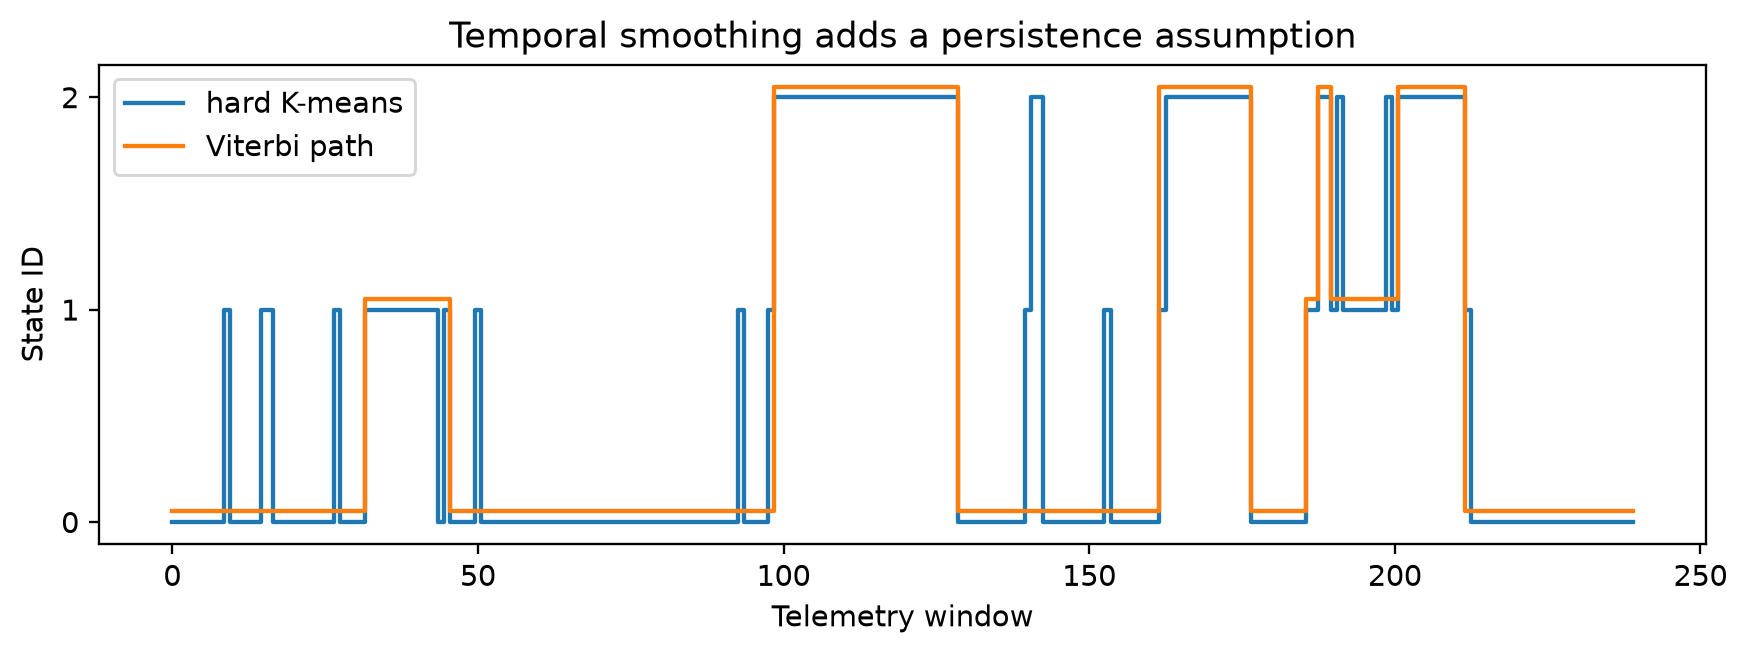

In [68]:
if RUN_BONUS_C:
    sticky_transition = np.full((3, 3), 0.04)
    np.fill_diagonal(sticky_transition, 0.92)
    start_probability = np.full(3, 1 / 3)
    smoothed_labels = viterbi_decode(
        np.log(responsibilities + 1e-12),
        sticky_transition,
        start_probability,
    )

    hard_switches = int(np.count_nonzero(np.diff(best_labels)))
    smooth_switches = int(np.count_nonzero(np.diff(smoothed_labels)))
    print("Hard K-means switches:", hard_switches)
    print("Viterbi-smoothed switches:", smooth_switches)

    plt.figure(figsize=(10, 3))
    plt.step(np.arange(len(best_labels)), best_labels, where="mid", label="hard K-means")
    plt.step(np.arange(len(smoothed_labels)), smoothed_labels + 0.05, where="mid", label="Viterbi path")
    plt.yticks([0, 1, 2])
    plt.xlabel("Telemetry window")
    plt.ylabel("State ID")
    plt.title("Temporal smoothing adds a persistence assumption")
    plt.legend()
    plt.show()


# Exploration Launchpad — keep going after you submit

Everything below is **ungraded**. The goal is not to collect more points; it is to poke the assumptions until the algorithms reveal where they are useful and where they get weird.

For runnable versions of the experiments, open **`DAML_HW03_Exploration_Studio.ipynb`** from the student release.

## Pick a route by time

| Time | Route | What you will learn |
|---|---|---|
| **10 minutes** | Initialization lottery + temperature dial | Why one clustering run is not evidence, and why “confidence” depends on a modeling choice |
| **25–35 minutes** | Scaling sabotage + choose $k$ + K-means failure gallery | How preprocessing and geometry can change the answer |
| **45–60 minutes** | PCA reconstruction + NMF programs | Two different meanings of “compress the data” |
| **60–90+ minutes** | Gaussian mixtures + Viterbi smoothing + autoencoder bridge | Soft clusters, sequence assumptions, and nonlinear representations |

A good exploration habit is: **predict first, run second, explain third**. Write down what you expect before touching the code. That tiny pause is where a lot of the learning lives.



## Six quick experiments you can run in this notebook

These snippets use variables already created above. Paste each one into a new code cell after completing the required work.

### 1. Initialization lottery

Run K-means from many seeds and inspect the spread in final inertia.

```python
inertias = []
for seed in range(50):
    labels, centers, history = fit_kmeans_guided(X, k=3, seed=seed)
    inertias.append(history[-1])

plt.figure(figsize=(7, 3))
plt.plot(inertias, marker="o")
plt.xlabel("Random seed")
plt.ylabel("Final inertia")
plt.title("Same data, different starts")
plt.show()
```

**Ask:** Are there several basins of attraction, or do most seeds converge to nearly the same solution?

### 2. Temperature dial

```python
for temperature in [0.25, 1.0, 3.0, 10.0]:
    R = soft_memberships(X, best_centers, temperature)
    print(
        f"temperature={temperature:>5}: "
        f"median confidence={np.median(R.max(axis=1)):.3f}"
    )
```

**Ask:** Did the data change? If not, why did the reported confidence change?

### 3. Scaling sabotage

```python
X_sabotaged = X.copy()
X_sabotaged[:, 0] *= 25
labels_scaled, centers_scaled, _ = fit_kmeans_guided(X_sabotaged, k=3, seed=best_run["seed"])
print("Agreement after rescaling one feature:",
      best_label_agreement(labels_scaled, best_labels, k=3))
```

**Ask:** Is Euclidean distance a fact about the data, or a choice about representation?



### 4. Sweep the number of clusters

```python
for k in range(2, 8):
    candidate_inertias = []
    for seed in range(10):
        labels_k, centers_k, history_k = fit_kmeans_guided(X, k=k, seed=seed)
        candidate_inertias.append(history_k[-1])
    print(f"k={k}: best inertia={min(candidate_inertias):.2f}")
```

**Ask:** Inertia always decreases as $k$ increases. What additional evidence would justify a particular $k$?

### 5. PCA reconstruction curve

```python
errors = []
for n_components in range(1, X.shape[1] + 1):
    Z, components, mean, ratio = pca_project(X, n_components)
    X_hat = Z @ components + mean
    errors.append(np.mean((X - X_hat) ** 2))

plt.figure(figsize=(6, 3))
plt.plot(range(1, X.shape[1] + 1), errors, marker="o")
plt.xlabel("Number of principal components")
plt.ylabel("Reconstruction MSE")
plt.title("Compression versus information loss")
plt.show()
```

**Ask:** Is the elbow sharp enough to support a clear compression choice?

### 6. Temporal stickiness

After completing Bonus C, vary the diagonal of the transition matrix.

```python
for stay_probability in [0.55, 0.75, 0.92, 0.99]:
    transition = np.full((3, 3), (1 - stay_probability) / 2)
    np.fill_diagonal(transition, stay_probability)
    path = viterbi_decode(
        np.log(responsibilities + 1e-12),
        transition,
        np.full(3, 1 / 3),
    )
    print(stay_probability, "switches:", np.count_nonzero(np.diff(path)))
```

**Ask:** At what point does useful smoothing become a refusal to believe real transitions?



## Guided tutorials — start here

### A. NumPy tools used in the homework

1. **NumPy broadcasting guide**  
   https://numpy.org/doc/stable/user/basics.broadcasting.html  
   Focus on the trailing-dimension rules, then return to the shape
   `X[:, None, :] - centers[None, :, :]`.

2. **NumPy SVD reference**  
   https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html  
   Trace the shapes of $U$, $S$, and $V^T$ and identify which object contains the PCA directions.

3. **NumPy beginner fundamentals**  
   https://numpy.org/doc/stable/user/absolute_beginners.html  
   Use this when indexing, `axis`, or array shapes—not the ML idea—is the part blocking you.

### B. Clustering from intuition to practice

4. **Google's full clustering course**  
   https://developers.google.com/machine-learning/clustering  
   This is the best single structured follow-up. It covers similarity, preprocessing, K-means, evaluation, and dimensionality reduction.

5. **Google: K-means step by step**  
   https://developers.google.com/machine-learning/clustering/kmeans/overview  
   Compare its assignment/update cycle with the functions you implemented.

6. **Google: clustering workflow**  
   https://developers.google.com/machine-learning/clustering/workflow  
   Pay special attention to preprocessing, similarity choice, and the need to interpret and revise clusters.

7. **Google: advantages and disadvantages of K-means**  
   https://developers.google.com/machine-learning/clustering/kmeans/advantages-disadvantages  
   Make a two-column list: assumptions satisfied by Orbital Black Box versus assumptions that remain questionable.

8. **scikit-learn: K-means assumption failure gallery**  
   https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html  
   Run the example, then explain each failure using geometry rather than memorized labels.

9. **scikit-learn: compare clustering algorithms**  
   https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html  
   Treat this as a model-selection map: shape, density, noise, and scale all matter.

10. **scikit-learn: silhouette analysis for choosing $k$**  
    https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html  
    Notice that a metric helps compare choices; it does not manufacture semantic truth.



## Soft clusters, decompositions, and sequences

### C. From hard K-means to EM and Gaussian mixtures

11. **scikit-learn Gaussian mixture guide**  
    https://scikit-learn.org/stable/modules/mixture.html  
    Connect covariance shape, soft responsibilities, E-steps, and M-steps.

12. **Stanford CS229 unsupervised-learning notes**  
    https://cs229.stanford.edu/materials.html  
    The relevant sequence is K-means, mixture of Gaussians, EM, factor analysis, and PCA. This is the math-forward route.

### D. PCA and NMF

13. **scikit-learn decomposition guide**  
    https://scikit-learn.org/stable/api/sklearn.decomposition.html  
    Use the API index to compare PCA, NMF, ICA, factor analysis, and truncated SVD.

14. **PCA on the Iris dataset**  
    https://scikit-learn.org/stable/auto_examples/decomposition/plot_pca_iris.html  
    Ask which visible separation is genuinely unsupervised and which interpretation comes from the known labels.

15. **Faces decomposed with PCA, NMF, ICA, and sparse methods**  
    https://scikit-learn.org/stable/auto_examples/decomposition/plot_faces_decomposition.html  
    This is a strong visual comparison of holistic versus parts-like components.

16. **Original NMF paper: “Learning the parts of objects”**  
    https://www.nature.com/articles/44565  
    Read the abstract and figures first. Then ask exactly how nonnegativity changes interpretability.

### E. Hidden states and nonlinear representations

17. **hmmlearn HMM tutorial**  
    https://hmmlearn.readthedocs.io/en/stable/tutorial.html  
    Follow the three core tasks: decode states, compute likelihood, and learn parameters.

18. **TensorFlow autoencoder tutorial**  
    https://www.tensorflow.org/tutorials/generative/autoencoder  
    It includes runnable Colab examples for compression, denoising, and anomaly detection.

19. **Original K-means++ paper**  
    https://theory.stanford.edu/~sergei/papers/kMeansPP-soda.pdf  
    This is the research-paper route for understanding why careful seeding matters.



## Mini-project menu

Choose one if you want to turn this homework into a portfolio-sized exploration.

1. **Cluster reliability report:** build a one-page report containing restart stability, silhouette score, cluster sizes, confidence histograms, and a written limitations section.
2. **Telemetry anomaly detector:** score each window by distance to its centroid, then investigate the highest-scoring windows without assuming they are truly anomalous.
3. **K-means versus GMM:** compare hard assignments, soft responsibilities, covariance assumptions, and uncertain points on the same data.
4. **PCA versus NMF:** compare reconstruction error and interpretability as the number of components changes.
5. **Sequence segmentation:** compare independent K-means labels with Viterbi-smoothed paths under several transition matrices.
6. **Clustering model card:** document the similarity metric, preprocessing, initialization, value of $k$, stability checks, intended use, and known failure modes.

### Final checkpoint

Before trusting any unsupervised result, be able to answer:

- What notion of similarity did I choose?
- Which preprocessing choices changed that similarity?
- How stable is the result across reasonable perturbations?
- Which model assumptions are doing the work?
- What external evidence would be needed to attach meaning to the discovered structure?

That last question is the whole game. A cluster can be mathematically crisp and semantically nonsense. Unsupervised learning is powerful; it is not clairvoyant.
